In [1]:
!pip install --upgrade --force-reinstall matplotlib matplotlib-inline pyadi-iio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 22.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 28.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 28.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 33.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 40.5 MB/s  0:00:00
  Attempting uninstall: tzdata
    Found existing installation: tzdata 2026.6
    Uninstalling tzdata-2026.6:
      Successfully uninstalled tzdata-2026.6
  Attempting uninstall: traitlets
    Found existing installation: traitlets 5.16.1
    Uninstalling traitlets-5.16.1:
      Successfully uninstalled traitlets-5.16.1
  Attempting uninstall: pyparsing━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  1/15 [traitlets]
    Found existing installation: pyparsing 3.3.3━━━━━━━━━━━━━━  1/15 [traitlets]
    Uninstalling pyparsing-3.3.3:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  1/15 [traitlets]
      Successfully uninstalled pypa

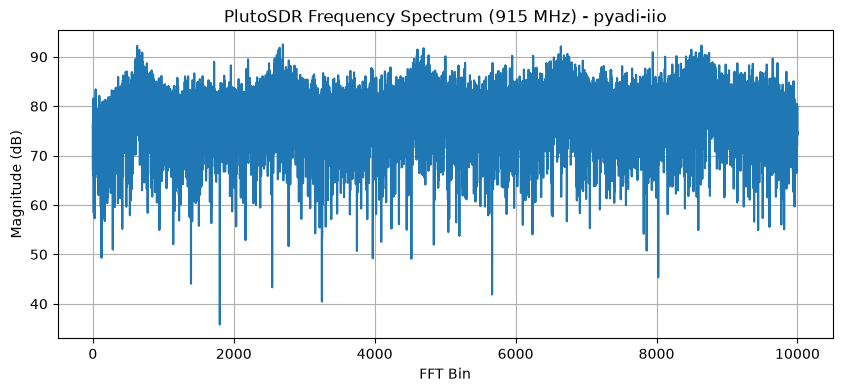

In [2]:
# Install pyadi-iio if not already installed
try:
    import adi
except ImportError:
    print("Installing pyadi-iio...")
    import subprocess
    subprocess.run(["pip", "install", "pyadi-iio"])
    import adi

import matplotlib.pyplot as plt
import numpy as np

# 1. Initialize the PlutoSDR device via its IP URI
sdr = adi.Pluto("ip:192.168.2.1")

# 2. Configure radio parameters
sdr.sample_rate = 2084000
sdr.rx_lo = 915000000
sdr.rx_buffer_size = 10000
sdr.gain_control_mode_chan0 = "slow_attack"

# 3. Capture a burst of IQ samples
samples = sdr.rx()

# 4. Compute and plot the frequency spectrum
fft_data = 20 * np.log10(np.abs(np.fft.fftshift(np.fft.fft(samples))))
plt.figure(figsize=(10, 4))
plt.plot(fft_data)
plt.title("PlutoSDR Frequency Spectrum (915 MHz) - pyadi-iio")
plt.xlabel("FFT Bin")
plt.ylabel("Magnitude (dB)")
plt.grid(True)
plt.show()